# Trabalho Final - Pipeline de Engenharia de Dados e ML: alerta antecipado de surtos de dengue

```
InfoDengue + Open-Meteo -> PostgreSQL -> ETL Python -> Features -> ML -> Metricas
```

| Etapa | Onde |
|---|---|
| Coleta (2 fontes) | `src/coleta.py` |
| Modelagem PostgreSQL | `sql/01_schema.sql` |
| ETL | `src/etl.py` |
| Features | `src/features.py` |
| Modelo e metricas | `src/modelo.py` |

**Problema:** classificacao binaria - havera surto (incidencia >= 50 casos/100 mil hab.) **daqui a 4 semanas**?

Neste notebook as etapas sao executadas de ponta a ponta.

## 1. Setup e fontes de dados

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from config import get_engine, LIMIAR_SURTO, HORIZONTE, ANO_TESTE
sns.set_theme(style="whitegrid")
eng = get_engine()
import coleta, etl, features, modelo
from config import RAW
print(len(list(RAW.glob('dengue_*.csv'))), 'arquivos de dengue |', len(list(RAW.glob('clima_*.csv'))), 'arquivos de clima')

12 arquivos de dengue | 12 arquivos de clima


## 2. ETL: CSVs brutos -> PostgreSQL
Cria o schema (`sql/01_schema.sql`), trata/valida e carrega as tabelas.

In [2]:
etl.main()

Validacoes OK | dengue=2496 linhas, clima=17532 linhas


dim_municipio: 12 linhas
dim_semana: 208 linhas
fato_dengue_semana: 2496 linhas
fato_clima_dia: 17532 linhas
vw_base_modelo: 2496 linhas


In [3]:
pd.read_sql("""select table_name, (xpath('/row/c/text()', query_to_xml('select count(*) as c from '||table_name, false, true, '')))[1]::text as linhas
from information_schema.tables where table_schema='public' order by 1""", eng)

,table_name,linhas
0,dim_municipio,12
1,dim_semana,208
2,fato_clima_dia,17532
3,fato_dengue_semana,2496
4,vw_base_modelo,2496
5,vw_clima_semana,2496


In [4]:
pd.read_sql('select * from vw_base_modelo order by geocode, se limit 5', eng)

,geocode,municipio,uf,se,data_ini,ano,semana,casos,casos_est,populacao,inc100k,nivel_alerta,rt,temp_media,temp_max,temp_min,precip_mm,umid_media
0,1302603,Manaus,AM,202101,2021-01-03,2021,1,65,65.0,2219580,2.9285,1,2.3249,26.085714,30.2,23.5,66.6,86.571429
1,1302603,Manaus,AM,202102,2021-01-10,2021,2,57,57.0,2219580,2.5681,1,1.9025,26.042857,29.9,22.9,28.2,86.142857
2,1302603,Manaus,AM,202103,2021-01-17,2021,3,83,83.0,2219580,3.7394,3,1.7606,25.557143,30.7,23.1,81.3,87.857143
3,1302603,Manaus,AM,202104,2021-01-24,2021,4,65,65.0,2219580,2.9285,1,1.0406,25.742857,29.0,23.1,34.3,87.571429
4,1302603,Manaus,AM,202105,2021-01-31,2021,5,122,122.0,2219580,5.4965,1,1.6769,26.814286,30.6,23.8,45.0,85.571429


## 3. Engenharia de features
- **Incidencia:** valor atual, lags 1-3, media movel 4s, variacao semanal e tendencia 4s.
- **Clima:** temperatura/umidade (atual, lag, media movel), chuva acumulada 4 e 8 semanas (efeito defasado no ciclo do mosquito).
- **Sazonalidade:** seno/cosseno da semana; **populacao** (log).
- **Alvo:** `surto_futuro` = incidencia em t+4 >= 50/100 mil.
- Sem vazamento: features usam apenas informacao ate a semana t.

In [5]:
features.main()
feats = features.criar_features(features.carregar_base(eng))
print(feats.shape)
feats[features.FEATURES + [features.ALVO]].describe().T.round(2)

features.csv: (2364, 28) | prevalencia do alvo = 14.7%
(2364, 28)


,count,mean,std,min,25%,50%,75%,max
inc_t,2364.0,40.56,118.72,0.00,3.55,9.67,25.90,1265.65
inc_lag1,2364.0,40.52,118.72,0.00,3.54,9.66,25.75,1265.65
inc_lag2,2364.0,40.48,118.73,0.00,3.52,9.66,25.49,1265.65
inc_lag3,2364.0,40.44,118.74,0.00,3.50,9.64,25.41,1265.65
inc_media4,2364.0,40.50,116.66,0.01,3.61,9.72,25.91,1221.00
inc_delta1,2364.0,0.04,23.19,-300.45,-1.43,-0.04,1.10,311.37
inc_tendencia4,2364.0,0.16,69.70,-685.24,-3.39,-0.15,2.49,746.32
nivel_alerta,2364.0,1.93,1.17,1.00,1.00,1.00,3.00,4.00
rt,2364.0,1.07,0.60,0.00,0.80,0.98,1.21,11.96
temp_media,2364.0,23.16,3.69,9.64,20.92,23.57,26.20,31.77


## 4. Treino e avaliacao
Split **temporal**: treino 2021-2023, teste 2024. Selecao por F1 em validacao cruzada temporal no treino. Baselines: classe majoritaria e persistencia (`incidencia atual >= 50`).

In [6]:
modelo.main()

treino=1788 (surto 10.2%) | teste=576 (surto 28.5%)


                       modelo  cv_f1_treino  accuracy  precision  recall     f1  roc_auc
      Baseline (persistencia)           NaN    0.8854     0.7663  0.8598 0.8103      NaN
Baseline (classe majoritaria)           NaN    0.7153     0.0000  0.0000 0.0000      NaN
          Regressao Logistica        0.6119    0.8351     0.6386  0.9695 0.7700   0.9659
                Random Forest        0.4993    0.8854     0.7552  0.8841 0.8146   0.9513
            Gradient Boosting        0.4807    0.8924     0.7833  0.8598 0.8198   0.9566



Melhor (CV F1): Regressao Logistica
{"accuracy": 0.8351, "precision": 0.6386, "recall": 0.9695, "f1": 0.77, "roc_auc": 0.9659}


                       modelo  cv_f1_treino  accuracy  precision  recall    f1  roc_auc
      Baseline (persistencia)           NaN     0.885      0.766   0.860 0.810      NaN
Baseline (classe majoritaria)           NaN     0.715      0.000   0.000 0.000      NaN
          Regressao Logistica         0.612     0.835      0.639   0.970 0.770    0.966
                Random Forest         0.499     0.885      0.755   0.884 0.815    0.951
            Gradient Boosting         0.481     0.892      0.783   0.860 0.820    0.957


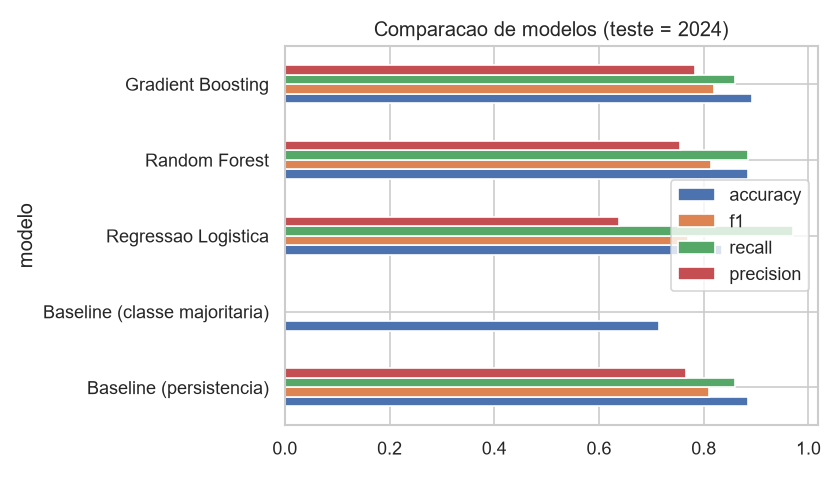

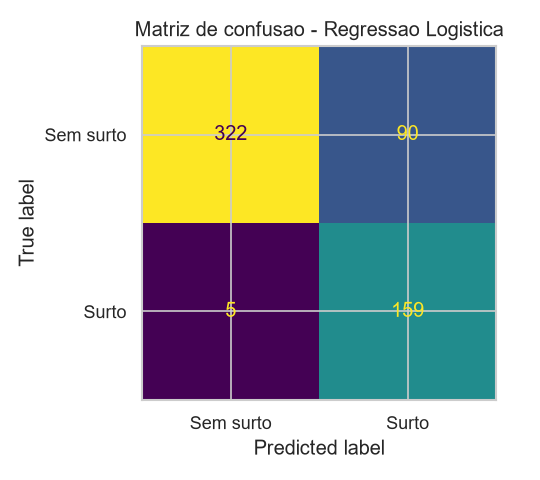

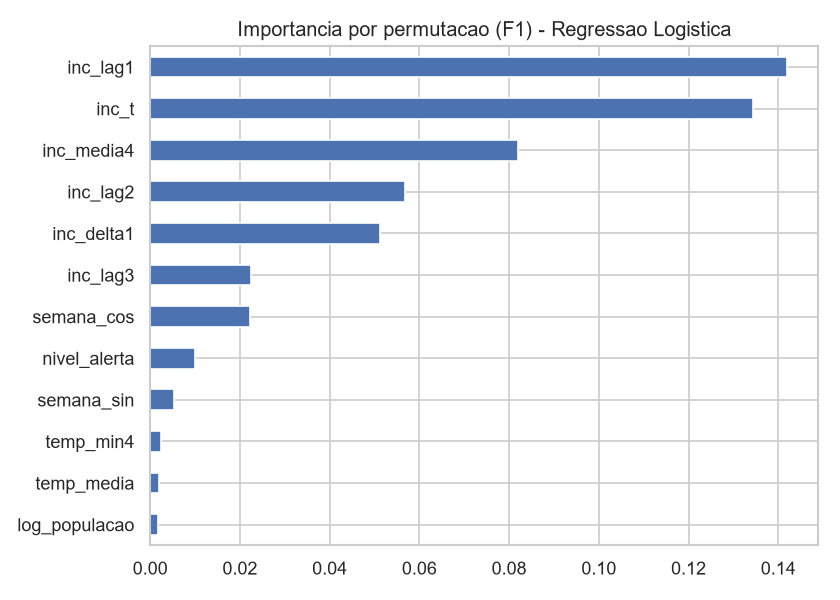

In [7]:
import pandas as pd
from IPython.display import Image, display
print(pd.read_csv('../reports/ranking_modelos.csv').round(3).to_string(index=False))
for f in ['comparacao_modelos','matriz_confusao','importancia_features']:
    display(Image(f'../reports/{f}.png'))

In [8]:
import json; print(json.dumps(json.load(open('../reports/metricas.json')), indent=2, ensure_ascii=False))

{
  "melhor_modelo": "Regressao Logistica",
  "metricas_teste": {
    "accuracy": 0.8351,
    "precision": 0.6386,
    "recall": 0.9695,
    "f1": 0.77,
    "roc_auc": 0.9659
  },
  "limiar_surto_inc100k": 50.0,
  "horizonte_semanas": 4,
  "ano_teste": 2024,
  "n_treino": 1788,
  "n_teste": 576,
  "prevalencia_treino": 0.1023,
  "prevalencia_teste": 0.2847,
  "top_features": {
    "inc_delta1": 0.0512,
    "inc_lag2": 0.0568,
    "inc_media4": 0.0819,
    "inc_t": 0.1343,
    "inc_lag1": 0.1418
  }
}


## 5. Analise dos resultados

- **Melhor modelo (por CV F1 no treino): Regressao Logistica**, com recall alto e ROC-AUC proximo de 0,97 no teste de 2024. Em vigilancia epidemiologica, recall alto (poucos surtos perdidos) e desejavel, ao custo de mais falsos alarmes (precisao menor).
- **Random Forest e Gradient Boosting** tem melhor F1/Accuracy no teste, proximos do baseline de persistencia; o ganho sobre ele e pequeno porque a incidencia atual ja carrega muita informacao a 4 semanas.
- **Accuracy** isolada engana: a classe majoritaria ja acerta ~71% no teste. Por isso F1, recall, precisao e ROC-AUC.
- **Limitacoes:** apenas 12 cidades e 4 anos; 2024 foi epidemico (mudanca de distribuicao entre treino e teste); poucos eventos de surto no treino (~10%); clima via reanalise (Open-Meteo), nao estacoes locais.
- **Proximos passos:** mais anos e municipios, features de mobilidade/vizinhanca, ajuste de limiar de decisao, modelos de regressao de incidencia.